# 03 Feature analysis（EDA）

Edited by Wang Kun


## 0. Function Definition and Basic Configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

# Run from SP500; all notebook helpers are local.
ROOT = Path.cwd().resolve()
if not (ROOT / "01_data_preprocessing.ipynb").is_file():
    raise FileNotFoundError("Run this notebook from the SP500 directory.")

### Path and Feature Config

In [2]:
DATA_DIR = ROOT / "data"

FEATURE_DIR = DATA_DIR / "features"

### Table, image and file saving

In [3]:
def save_csv(path, frame, index=True):
    frame.to_csv(path, index=index, encoding="utf-8-sig", index_label="signal_date" if index else None)

def show_table(frame, decimals=4):
    """Display rounded values without changing saved data."""
    display(frame.round(decimals))

def show_figure(fig, path):
    """Save and display the figure."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)

## 1. Import and path checking

In [4]:
DATA_DIR = ROOT / "data" / "splits"
OUTPUT_DIR = ROOT / "output" / "feature_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SPLITS = ("train", "val", "test")
LABELS = {"train": "Train", "val": "Validation", "test": "Test"}
sns.set_theme(style="whitegrid")
plt.rcParams["axes.unicode_minus"] = False
for path in [FEATURE_DIR / "sp500_features.csv", FEATURE_DIR / "sp500_labels.csv",
             *[DATA_DIR / f"sp500_{name}.csv" for name in SPLITS]]:
    if not path.is_file():
        raise FileNotFoundError(f"Run steps 01 and 02; missing: {path.name}")

## 2. Read features and labels

In [5]:
features = pd.read_csv(FEATURE_DIR / "sp500_features.csv", index_col="signal_date",
                       parse_dates=["signal_date"]).sort_index()
labels = pd.read_csv(FEATURE_DIR / "sp500_labels.csv", index_col="signal_date",
                     parse_dates=["signal_date", "trade_date", "settle_date"]).sort_index()
original_splits = {}
for name in SPLITS:
    frame = pd.read_csv(DATA_DIR / f"sp500_{name}.csv", parse_dates=["date"]).sort_values("date")
    assert not frame.empty and frame.date.notna().all() and frame.date.is_unique
    original_splits[name] = frame
# check consistency
assert features.index.is_unique and features.index.equals(labels.index)
assert features.shape[1] == 14 and not np.isinf(features.to_numpy()).any()
val_start = original_splits["val"].date.min()
test_start = original_splits["test"].date.min()
# ensure that the time ranges of different data sets don't overlap
assert original_splits["train"].date.max() < val_start
assert original_splits["val"].date.max() < test_start
all_dates = pd.DatetimeIndex(pd.concat([original_splits[s].date for s in SPLITS]))
assert all_dates.is_unique
assert labels.index.isin(all_dates).all()
assert labels.trade_date.isin(all_dates).all() and labels.settle_date.isin(all_dates).all()
print(f"Features {features.shape}; labels {labels.shape}")
show_table(features.head(3))

Features (7545, 14); labels (7545, 4)


,return_1d,return_5d,return_20d,volatility_20d,intraday_return,intraday_range,close_vs_sma20,sma5_vs_sma20,overnight_return,close_location,volatility_5d,avg_intraday_range_20d,volume_change_1d,volume_vs_prev20
signal_date,,,,,,,,,,,,,,
1996-11-13,NaN,NaN,NaN,NaN,0.0022,0.0056,NaN,NaN,NaN,0.7598,NaN,NaN,NaN,NaN
1996-11-14,0.0065,NaN,NaN,NaN,0.0065,0.0093,NaN,NaN,0.0,0.9838,NaN,NaN,0.1175,NaN
1996-11-15,0.0024,NaN,NaN,NaN,0.0024,0.0092,NaN,NaN,0.0,0.3648,NaN,NaN,0.1015,NaN


## 3. Data leakage check

> filter valid samples in each data set and delete samples that cross time boundaries to prevent future information leakage.

> If the selling date of a training sample enters the validation set, the sample needs to be deleted, otherwise the future information in the validation set may be used during training.

In [6]:
split_data, summary_rows = {}, []  # Check every split separately
for name in SPLITS:
    dates = pd.DatetimeIndex(original_splits[name].date)
    candidates = labels.loc[labels.index.isin(dates)]
    # Train targets must settle before the validation boundary.
    safe_labels = candidates.loc[candidates.trade_date.isin(dates) & candidates.settle_date.isin(dates)]
    split_data[name] = {"X": features.loc[safe_labels.index], "labels": safe_labels,
                        "y_reg": safe_labels.target_return.astype(float),
                        "y_cls": safe_labels.target_class.astype(int)}
    assert len(safe_labels) > 0
    summary_rows.append({"split": name, "candidates": len(candidates), "samples": len(safe_labels),
                         "removed_boundary": len(candidates) - len(safe_labels),
                         "first_signal": safe_labels.index.min(), "last_signal": safe_labels.index.max(),
                         "last_settlement": safe_labels.settle_date.max()})
# Check that the splits are strictly sequential in time.
assert split_data["train"]["labels"].settle_date.max() < split_data["val"]["X"].index.min()
assert split_data["val"]["labels"].settle_date.max() < split_data["test"]["X"].index.min()
summary = pd.DataFrame(summary_rows)
save_csv(OUTPUT_DIR / "split_summary.csv", summary, index=False)
show_table(summary)

C:\Users\w\AppData\Local\Temp\ipykernel_36144\3388859954.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(frame.round(decimals))


,split,candidates,samples,removed_boundary,first_signal,last_signal,last_settlement
0,train,6037,6035,2,1996-11-13,2020-11-04,2020-11-06
1,val,755,753,2,2020-11-09,2023-11-06,2023-11-08
2,test,753,753,0,2023-11-09,2026-11-10,2026-11-12


## 4. Exploratory Data Analysis (EDA)

> Count the missing values, category distribution and return distribution of the training set, validation set and test set, and observe whether there is category imbalance and distribution difference in the data through visualization

missing_values


,index,Train,Validation,Test,Total
0,return_1d,1,0,0,1
1,return_5d,5,0,0,5
2,return_20d,20,0,0,20
3,volatility_20d,20,0,0,20
4,intraday_return,0,0,0,0
5,intraday_range,0,0,0,0
6,close_vs_sma20,19,0,0,19
7,sma5_vs_sma20,19,0,0,19
8,overnight_return,1,0,0,1
9,close_location,0,0,0,0


class_distribution


,target_class,Train,Validation,Test
0,0,3465,436,427
1,1,2570,317,326


return_statistics


,index,Train,Validation,Test
0,count,6035.0000,753.0000,753.0000
1,mean,0.0329,0.0336,0.0771
2,std,1.1708,1.0326,0.9296
3,min,-8.7119,-3.9113,-6.3934
4,25%,-0.4800,-0.4958,-0.3280
5,50%,0.0735,0.0659,0.1046
6,75%,0.5832,0.6478,0.5735
7,max,10.6712,4.8302,7.8116


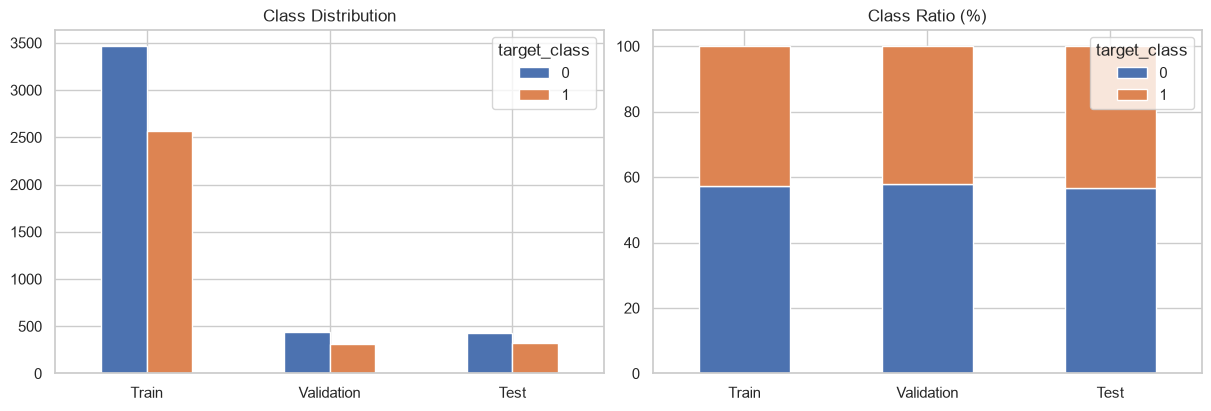

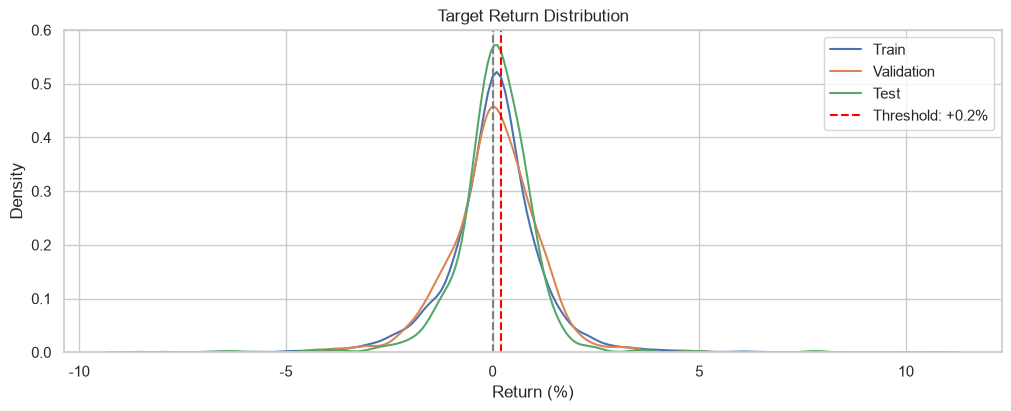

In [7]:
# missing values
missing_report = pd.DataFrame({LABELS[s]: split_data[s]["X"].isna().sum() for s in SPLITS})
missing_report["Total"] = missing_report.sum(axis=1)
# class distribution and return statistics
class_report = pd.DataFrame({LABELS[s]: split_data[s]["y_cls"].value_counts().reindex([0, 1], fill_value=0)
                             for s in SPLITS})
return_report = pd.DataFrame({LABELS[s]: split_data[s]["y_reg"].describe() * 100 for s in SPLITS})
return_report.loc["count"] /= 100
for name, table in (("missing_values", missing_report), ("class_distribution", class_report),
                    ("return_statistics", return_report)):
    print(name)
    show_table(table.reset_index())
    table.to_csv(OUTPUT_DIR / f"{name}.csv", encoding="utf-8-sig")

# visualization plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
class_report.T.plot.bar(ax=axes[0], rot=0, title="Class Distribution")
ratios = class_report.div(class_report.sum(axis=0), axis=1).T * 100
ratios.plot.bar(ax=axes[1], stacked=True, rot=0, title="Class Ratio (%)")
show_figure(fig, OUTPUT_DIR / "class_distribution.png")

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
for name in SPLITS:
    sns.kdeplot(split_data[name]["y_reg"] * 100, label=LABELS[name], warn_singular=False, ax=ax)
ax.axvline(0, color="gray", linestyle="--")
ax.axvline(0.2, color="red", linestyle="--", label="Threshold: +0.2%")
ax.set(xlabel="Return (%)", title="Target Return Distribution")
ax.legend()
show_figure(fig, OUTPUT_DIR / "return_distribution.png")

## 5. Feature correlation analysis of training set

> Study the relationship between 14 features, as well as the relationship between each feature and classification and regression targets. Use correlation coefficients, heat maps, and histograms to determine whether there are redundant features and understand the potential predictive value of each feature.

,index,target_return,target_class
0,return_1d,-0.0684,-0.0731
1,return_5d,-0.0764,-0.0690
2,return_20d,-0.0375,-0.0551
3,volatility_20d,0.0142,0.0589
4,intraday_return,-0.0683,-0.0720
5,intraday_range,0.0316,0.0509
6,close_vs_sma20,-0.0560,-0.0701
7,sma5_vs_sma20,-0.0305,-0.0474
8,overnight_return,-0.0208,-0.0272
9,close_location,-0.0475,-0.0830


,Feature A,Feature B,Abs Correlation
4,return_1d,intraday_return,0.9755
53,volatility_20d,avg_intraday_range_20d,0.9649
91,close_vs_sma20,sma5_vs_sma20,0.8915


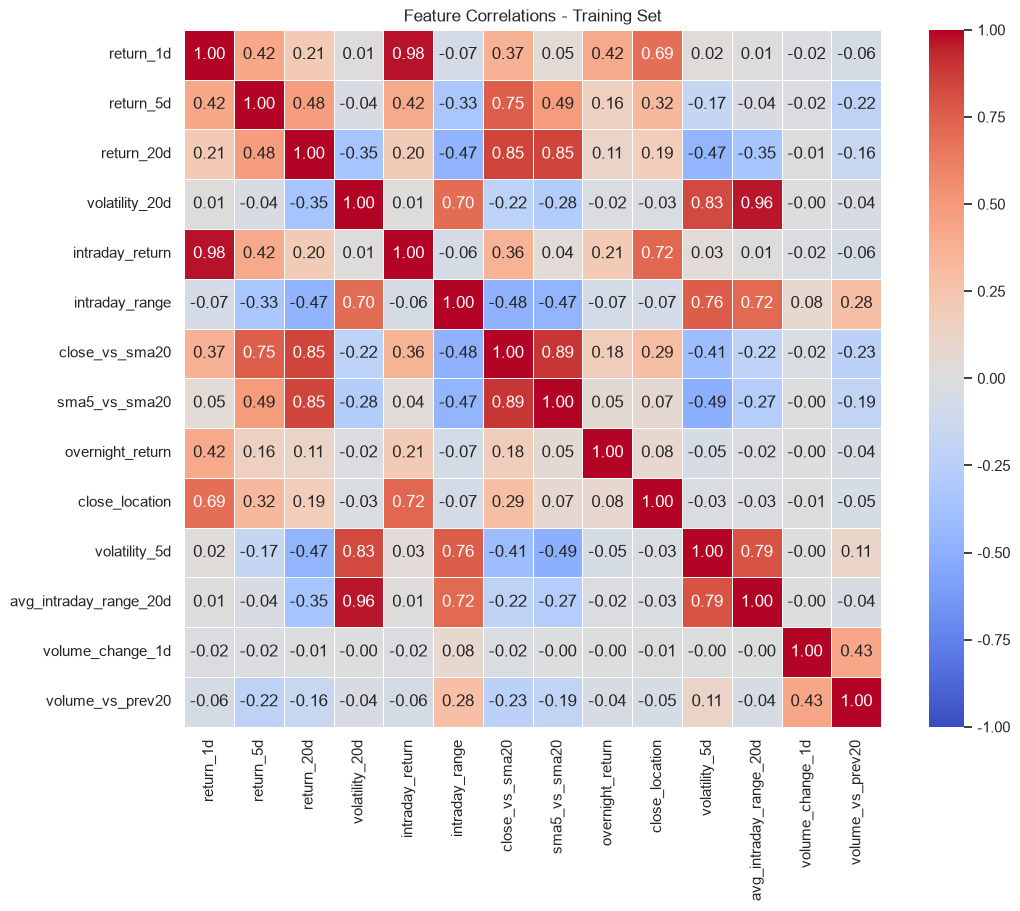

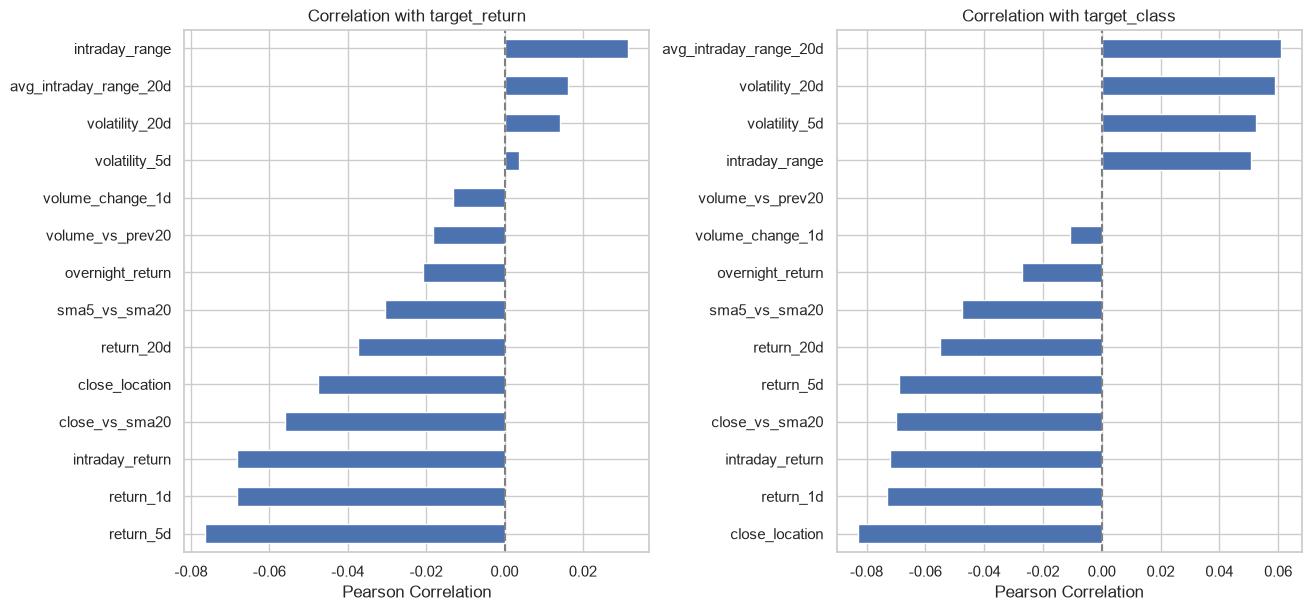

In [8]:
X_train = split_data["train"]["X"]
corr_matrix = X_train.corr(method="pearson")  # Fit correlations on training dates only
# calculate the correlation between features and targets
target_corr = X_train.join(split_data["train"]["labels"][["target_return", "target_class"]]).corr()
target_corr = target_corr.loc[features.columns, ["target_return", "target_class"]]
# filter for highly relevant features
# # Take the absolute value of the correlation coefficient, and retain the upper triangular part of the matrix
upper = corr_matrix.abs().where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
# the correlation coefficient matrix -> a feature pairing table
high_corr = upper.stack().reset_index()
high_corr.columns = ["Feature A", "Feature B", "Abs Correlation"]
# Filter feature combinations whose absolute correlation coefficient is greater than or equal to 0.85
high_corr = high_corr.loc[high_corr["Abs Correlation"] >= 0.85].sort_values("Abs Correlation", ascending=False)
show_table(target_corr.reset_index())
show_table(high_corr)
corr_matrix.to_csv(OUTPUT_DIR / "feature_correlations.csv", encoding="utf-8-sig")
target_corr.to_csv(OUTPUT_DIR / "target_correlations.csv", encoding="utf-8-sig")
save_csv(OUTPUT_DIR / "high_correlations.csv", high_corr, index=False)

fig, ax = plt.subplots(figsize=(11, 9), constrained_layout=True)
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.4, ax=ax)
ax.set_title("Feature Correlations - Training Set")
show_figure(fig, OUTPUT_DIR / "feature_correlations.png")

fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
for ax, target in zip(axes, ["target_return", "target_class"]):
    target_corr[target].sort_values().plot.barh(ax=ax)
    ax.axvline(0, color="gray", linestyle="--")
    ax.set(title=f"Correlation with {target}", xlabel="Pearson Correlation")
show_figure(fig, OUTPUT_DIR / "target_correlations.png")

## 6. Annual return and category ratio analysis

> By counting the average returns, volatility and positive category proportions in different years, we can observe changes in the market over time and whether there are differences in data distribution in different time periods.

,year,sample_count,mean_return,positive_ratio,return_std
0,2017,251,0.0007,0.3506,0.0037
1,2018,251,-0.0003,0.4143,0.0105
2,2019,252,0.0010,0.4603,0.0069
3,2020,251,0.0006,0.5299,0.0158
4,2021,252,0.0011,0.4048,0.0073
5,2022,251,-0.0008,0.4382,0.0141
6,2023,248,0.0009,0.4194,0.0081
7,2024,252,0.0009,0.4405,0.0076
8,2025,250,0.0007,0.4200,0.0120
9,2026,216,0.0005,0.4259,0.0078


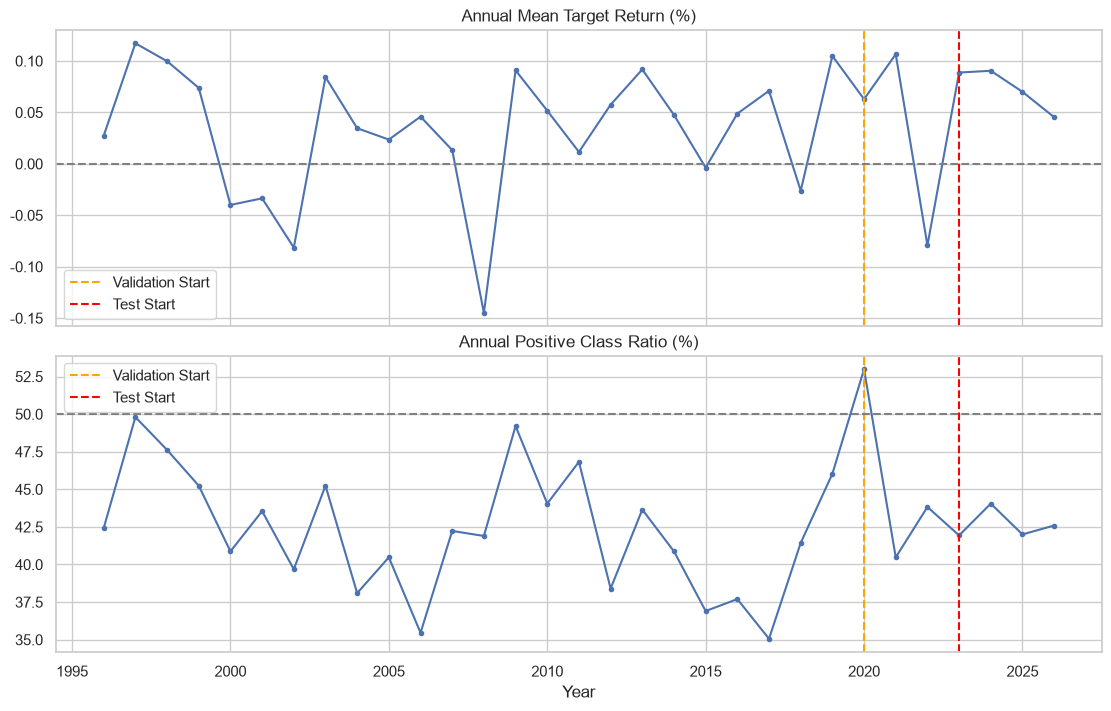

Feature analysis saved under output/feature_analysis.


In [9]:
plot_data = pd.concat([split_data[s]["labels"] for s in SPLITS]).sort_index()
# group by year, and calculate statistical indicators for each year
yearly_stats = plot_data.groupby(plot_data.index.year).agg(
    sample_count=("target_return", "size"), mean_return=("target_return", "mean"),
    positive_ratio=("target_class", "mean"), return_std=("target_return", "std"))
yearly_stats.index.name = "year"
yearly_stats.to_csv(OUTPUT_DIR / "yearly_statistics.csv", encoding="utf-8-sig")
show_table(yearly_stats.tail(10).reset_index())

# visualization
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, constrained_layout=True)
for ax, metric, title in ((axes[0], "mean_return", "Annual Mean Target Return (%)"),
                          (axes[1], "positive_ratio", "Annual Positive Class Ratio (%)")):
    ax.plot(yearly_stats.index, yearly_stats[metric] * 100, marker="o", markersize=3)
    ax.axvline(val_start.year, color="orange", linestyle="--", label="Validation Start")
    ax.axvline(test_start.year, color="red", linestyle="--", label="Test Start")
    ax.set_title(title)
    ax.legend()
axes[0].axhline(0, color="gray", linestyle="--")
axes[1].axhline(50, color="gray", linestyle="--")
axes[1].set_xlabel("Year")
show_figure(fig, OUTPUT_DIR / "yearly_statistics.png")
print("Feature analysis saved under output/feature_analysis.")

## Supplement: Income distribution and sustainability - Tail Analysis & Autocorrelation Analysis

Mainly research three questions:
- Do financial returns follow a normal distribution?
- Do extreme ups and downs occur more frequently than in a normal distribution?
- Is there a temporal correlation between historical returns and market volatility?

In [10]:
import json, hashlib, platform, sys
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, balanced_accuracy_score, accuracy_score, f1_score, r2_score
ROOT = Path.cwd().resolve()
assert (ROOT / '01_data_preprocessing.ipynb').is_file()
FEATURES = ['return_1d','return_5d','return_20d','volatility_20d','intraday_return','intraday_range']

def read_frame(path):
    f = pd.read_csv(path, index_col='signal_date', float_precision='round_trip')
    f.index = pd.to_datetime(f.index)
    for c in ['trade_date','settle_date']:
        if c in f: f[c] = pd.to_datetime(f[c])
    assert f.index.is_unique and f.index.is_monotonic_increasing
    return f

def write_json(path, obj):
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

def new_output(name):
    out = ROOT / 'output' / 'fusion' / name / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
    out.mkdir(parents=True)
    write_json(out/'environment.json', {'python':sys.version,'executable':sys.executable,'numpy':np.__version__,'pandas':pd.__version__})
    inputs = list((ROOT/'data/features').glob('*.csv')) + list((ROOT/'data/processed').glob('*.csv'))
    write_json(out/'fingerprints.json', {str(f.relative_to(ROOT)):hashlib.sha256(f.read_bytes()).hexdigest() for f in inputs})
    return out

standardized formula: 
$$
z=\frac{x-\mu}{\sigma}
$$

,n,skew,excess_kurtosis,abs_z_over_3,normal_reference
0,6020,-0.159719,7.458254,0.014618,0.0027


Non-overlapping 20-session volatility lag-1 correlation: 0.7185507765988026


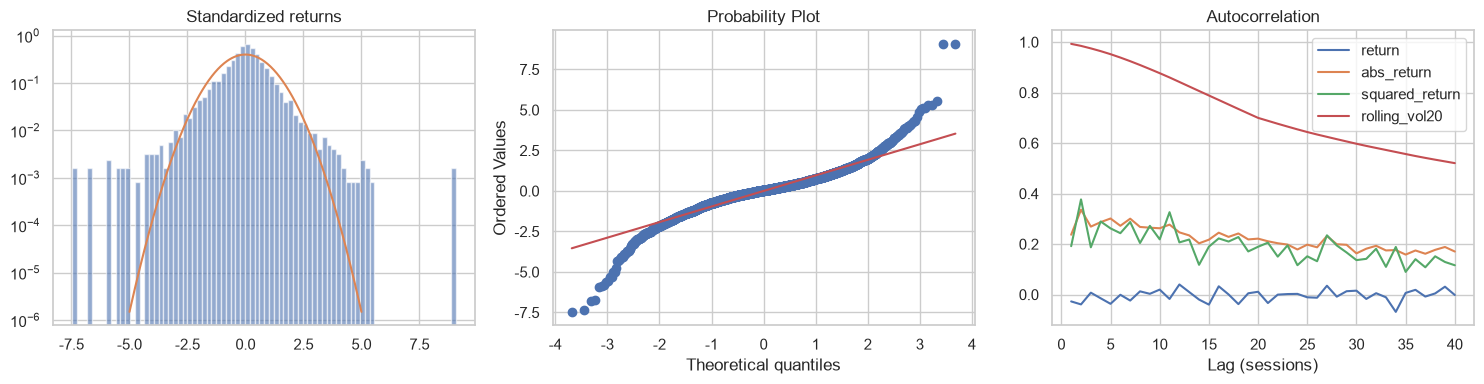

In [11]:
from scipy import stats
OUT = new_output('03_tail_analysis')
# Filter training data, prevent data leakage
r = read_frame(ROOT/'data/features/regression_samples.csv')
nval = ntest = round(len(r)*0.1)
cut = r.iloc[len(r)-nval-ntest].trade_date
r = r.loc[r.settle_date < cut, 'target_return']

# Tail Analysis
z = (r-r.mean())/r.std()
summary = pd.DataFrame([{'n':len(r),        # sample size
                         'skew':r.skew(),       # skewness
                         'excess_kurtosis':r.kurt(),        # excess kurtosis
                        'abs_z_over_3':(abs(z)>3).mean(),       # proportion of extreme gains
                        'normal_reference':2*stats.norm.sf(3)}])
summary.to_csv(OUT/'tail_summary.csv',index=False)
display(summary)

# Autocorrelation Analysis
lags = range(1,41)      # set lag period from 1 to 40 trading days
series = {'return':r,       # original yield
          'abs_return':r.abs(),     # absolute yield
          'squared_return':r**2,        # square yield
          'rolling_vol20':r.rolling(20).std().dropna()}
acf = pd.DataFrame({k:[v.autocorr(i) for i in lags] for k,v in series.items()},index=lags)      # calculate autocorrelation for each series at each lag
acf.to_csv(OUT/'acf.csv')

# Non-overlapping window volatility analysis
block_vol = r.groupby(np.arange(len(r))//20).std().dropna()
print('Non-overlapping 20-session volatility lag-1 correlation:',block_vol.autocorr())      # calculate the correlation of adjacent volatility windows
fig, axes = plt.subplots(1,3,figsize=(15,4))
axes[0].hist(z,bins=80,density=True,alpha=.6); x=np.linspace(-5,5,300)
axes[0].plot(x,stats.norm.pdf(x)); axes[0].set(title='Standardized returns',yscale='log')
stats.probplot(z,dist='norm',plot=axes[1])
acf.plot(ax=axes[2]); axes[2].set(title='Autocorrelation',xlabel='Lag (sessions)')
fig.tight_layout(); fig.savefig(OUT/'tail_acf.png'); display(fig); plt.close(fig)